# 1. SETUP & BIG DATA LOADING
*Using PyArrow to safely load a time-representative sample of a 15-million-row Parquet file without crashing RAM.*

In [1]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = r"C:\CreditRiskCourse\data\raw\New folder\credit_card_fraud.parquet"
parquet_file = pq.ParquetFile(file_path)

# Extract a sample from each row group to preserve the timeline
samples_per_group = 5000 
sampled_dfs = []

print("Extracting time-representative sample...")
for i in range(parquet_file.num_row_groups):
    chunk_df = parquet_file.read_row_group(i).to_pandas()
    n_samples = min(samples_per_group, len(chunk_df))
    sampled_dfs.append(chunk_df.sample(n=n_samples, random_state=42))

df = pd.concat(sampled_dfs, ignore_index=True)
del sampled_dfs
import gc; gc.collect()

print(f"✅ Final Sample Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

Extracting time-representative sample...
✅ Final Sample Shape: 2,400,000 rows, 34 columns


# 2. DATA AUDIT & CLEANING
*Dropping unique identifiers (to prevent memorization) and checking categorical cardinality.*

In [2]:
print(f"Target Distribution:\n{df['is_fraud'].value_counts(normalize=True) * 100}")

# Drop Leakage/ID Columns
cols_to_drop = ['transaction_id', 'customer_id']
df_clean = df.drop(columns=cols_to_drop, errors='ignore')

# Drop high cardinality text columns (if any > 50 unique values)
cat_cols = df_clean.select_dtypes(include=['object', 'string']).columns
high_card = [col for col in cat_cols if df_clean[col].nunique() > 50]
if high_card:
    df_clean = df_clean.drop(columns=high_card)

print(f"✅ Data Cleaned. Final Shape: {df_clean.shape}")

Target Distribution:
is_fraud
0    95.098417
1     4.901583
Name: proportion, dtype: float64
✅ Data Cleaned. Final Shape: (2400000, 32)


# 3. EXPLORATORY DATA ANALYSIS (EDA)
*Understanding the business signals of fraud before modeling.*

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11996\67945500.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cvv_fraud.index, y=cvv_fraud.values, ax=axes[0, 0], palette='Reds_r')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11996\67945500.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=merch_fraud.index, y=merch_fraud.values, ax=axes[0, 1], palette='Oranges_r')
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11996\67945500.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=geo_fraud.index, y=geo_fraud.values, ax=axes[1, 1], pal

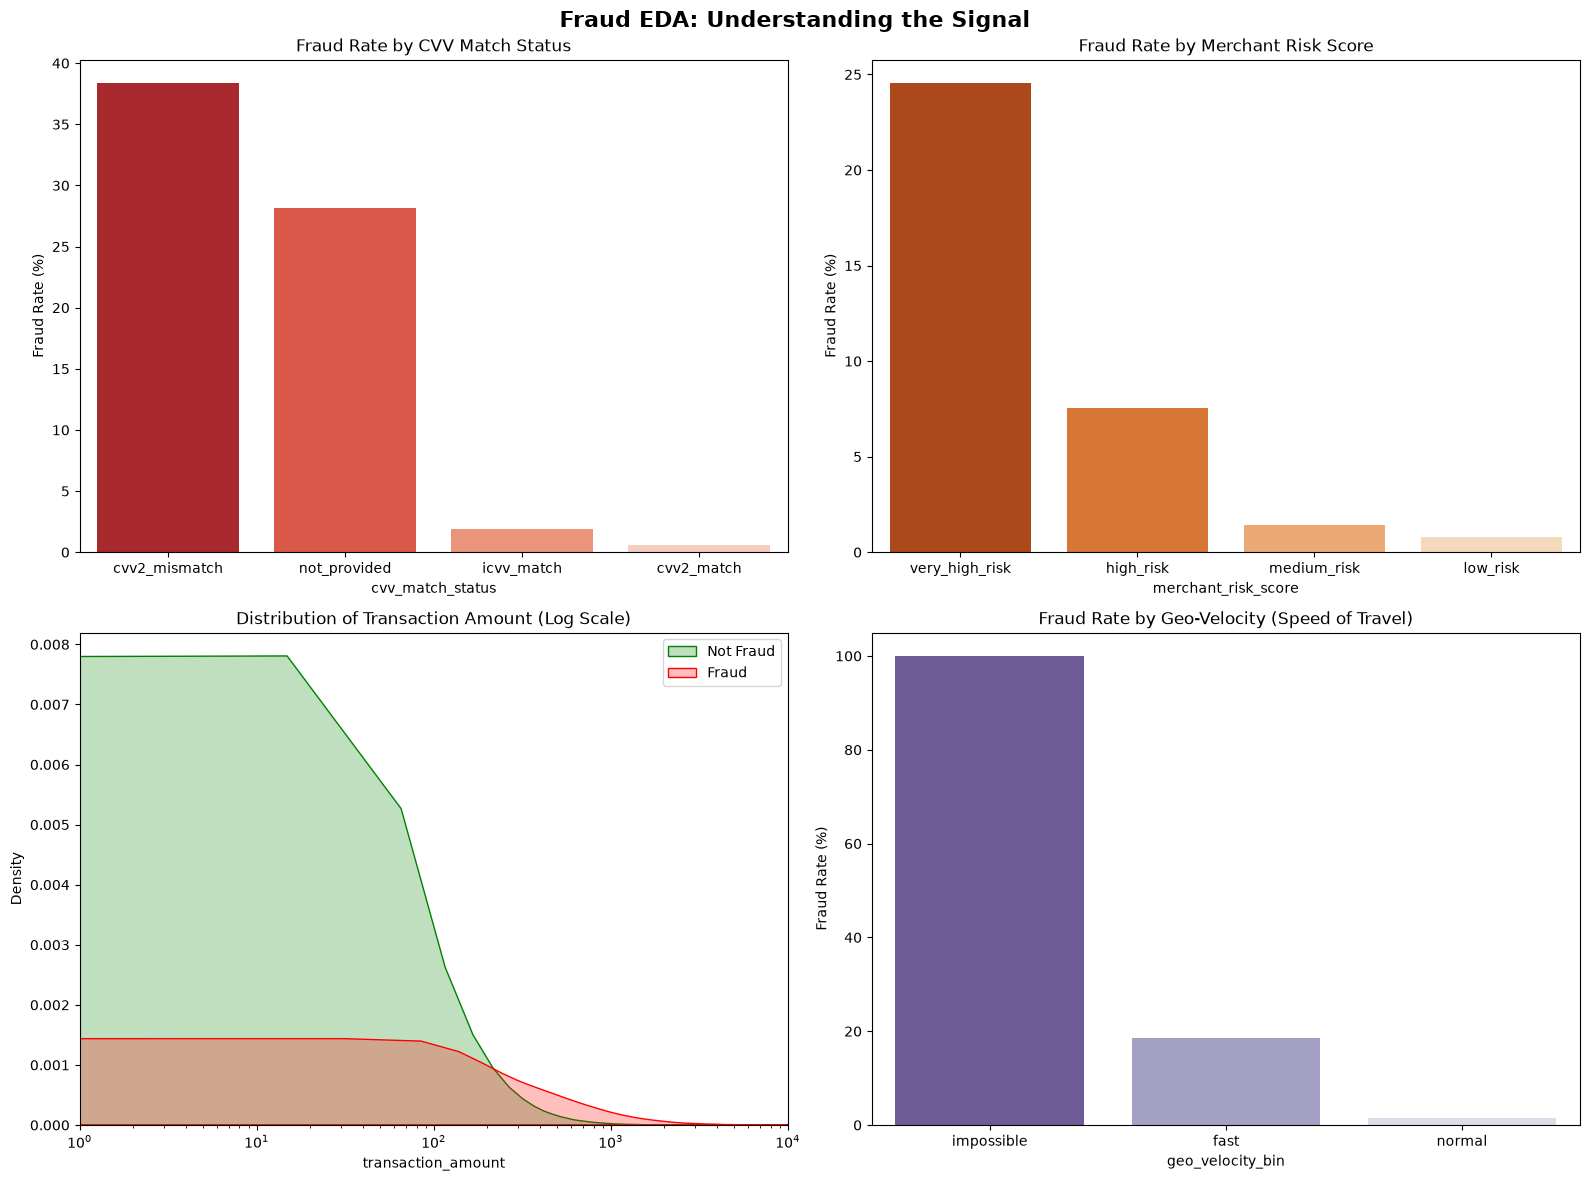

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# We use df_clean (which still has the text categories, making plots easier to read)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Fraud EDA: Understanding the Signal', fontsize=16, fontweight='bold')

# 1. Fraud Rate by CVV Match Status
# Hypothesis: If CVV doesn't match, fraud rate should be much higher.
cvv_fraud = df_clean.groupby('cvv_match_status')['is_fraud'].mean().sort_values(ascending=False) * 100
sns.barplot(x=cvv_fraud.index, y=cvv_fraud.values, ax=axes[0, 0], palette='Reds_r')
axes[0, 0].set_title('Fraud Rate by CVV Match Status')
axes[0, 0].set_ylabel('Fraud Rate (%)')

# 2. Fraud Rate by Merchant Risk Score
# Hypothesis: High-risk merchants should have higher fraud rates.
merch_fraud = df_clean.groupby('merchant_risk_score')['is_fraud'].mean().sort_values(ascending=False) * 100
sns.barplot(x=merch_fraud.index, y=merch_fraud.values, ax=axes[0, 1], palette='Oranges_r')
axes[0, 1].set_title('Fraud Rate by Merchant Risk Score')
axes[0, 1].set_ylabel('Fraud Rate (%)')

# 3. Distribution of Transaction Amount (Fraud vs Non-Fraud)
# Hypothesis: Fraudsters might test with small amounts or try huge amounts.
sns.kdeplot(data=df_clean[df_clean['is_fraud'] == 0], x='transaction_amount', label='Not Fraud', ax=axes[1, 0], fill=True, color='green')
sns.kdeplot(data=df_clean[df_clean['is_fraud'] == 1], x='transaction_amount', label='Fraud', ax=axes[1, 0], fill=True, color='red')
axes[1, 0].set_title('Distribution of Transaction Amount (Log Scale)')
axes[1, 0].set_xscale('log') # Log scale because amounts vary wildly
axes[1, 0].set_xlim(1, 10000)
axes[1, 0].legend()

# 4. Fraud Rate by Geo Velocity Bin
# Hypothesis: Impossible travel (high velocity) is a huge fraud signal.
geo_fraud = df_clean.groupby('geo_velocity_bin')['is_fraud'].mean().sort_values(ascending=False) * 100
sns.barplot(x=geo_fraud.index, y=geo_fraud.values, ax=axes[1, 1], palette='Purples_r')
axes[1, 1].set_title('Fraud Rate by Geo-Velocity (Speed of Travel)')
axes[1, 1].set_ylabel('Fraud Rate (%)')

plt.tight_layout()
plt.show()

# 4. ENCODING, SPLITTING & MULTICOLLINEARITY
*One-Hot encoding, stratified splitting, and removing redundant/leakage features.*

In [4]:
from sklearn.model_selection import train_test_split

# One-Hot Encode
df_encoded = pd.get_dummies(df_clean, drop_first=True, dtype=np.int8)

# Drop Collinear & Leakage Traps found in the Correlation Matrix
cols_to_drop = [
    'transaction_amount_bin_low', 'transaction_amount_bin_medium', 'transaction_amount_bin_very_high',
    'geo_velocity_bin_impossible', 'geo_velocity_bin_fast', 'geo_distance_bin_short', 
    'geo_distance_bin_same_location', 'session_duration_bin_slow', 'session_duration_bin_normal',
    'merchant_category_vs_history_no_history', 'account_credential_change_recency_not_applicable',
    'customer_type_global', 'cards_on_device_30d'
]
df_final = df_encoded.drop(columns=cols_to_drop, errors='ignore')

# Split
X = df_final.drop(columns=['is_fraud'])
y = df_final['is_fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 5. CHAMPION MODEL (LOGISTIC REGRESSION)
*Training a baseline model using class balancing to handle the 5% fraud rate.*

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_sc, y_train)

y_pred_lr = lr_model.predict_proba(X_test_sc)[:, 1]
print(f"Champion AUC-PR: {average_precision_score(y_test, y_pred_lr):.4f}")

Champion AUC-PR: 0.9924


# 6. CHALLENGER MODEL (XGBOOST)
*Training an XGBoost model to capture non-linear interactions.*

Challenger AUC-PR: 0.9920

--- XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    684709
           1       0.97      0.98      0.97     35291

    accuracy                           1.00    720000
   macro avg       0.98      0.99      0.99    720000
weighted avg       1.00      1.00      1.00    720000



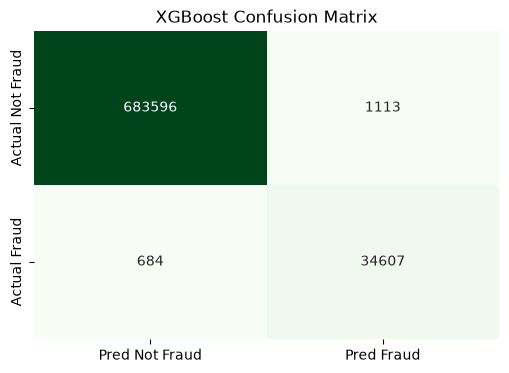

In [6]:
import xgboost as xgb
from sklearn.metrics import confusion_matrix

scale_weight = (len(y_train) - y_train.sum()) / y_train.sum()
xgb_fraud = xgb.XGBClassifier(n_estimators=150, max_depth=5, learning_rate=0.05, 
                              scale_pos_weight=scale_weight, random_state=42, eval_metric="aucpr", n_jobs=-1)
xgb_fraud.fit(X_train, y_train)

y_pred_xgb = xgb_fraud.predict_proba(X_test)[:, 1]
y_pred_bin = (y_pred_xgb >= 0.50).astype(int)

print(f"Challenger AUC-PR: {average_precision_score(y_test, y_pred_xgb):.4f}")
print("\n--- XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_bin, zero_division=0))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_bin)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Pred Not Fraud', 'Pred Fraud'],
            yticklabels=['Actual Not Fraud', 'Actual Fraud'])
plt.title('XGBoost Confusion Matrix')
plt.savefig(r"C:\CreditRiskCourse\fraud_confusion_matrix.png", dpi=150) # Save for GitHub
plt.show()

# 7. FEATURE IMPORTANCE & EXPORT
*Extracting the top fraud drivers and saving the model for Streamlit.*

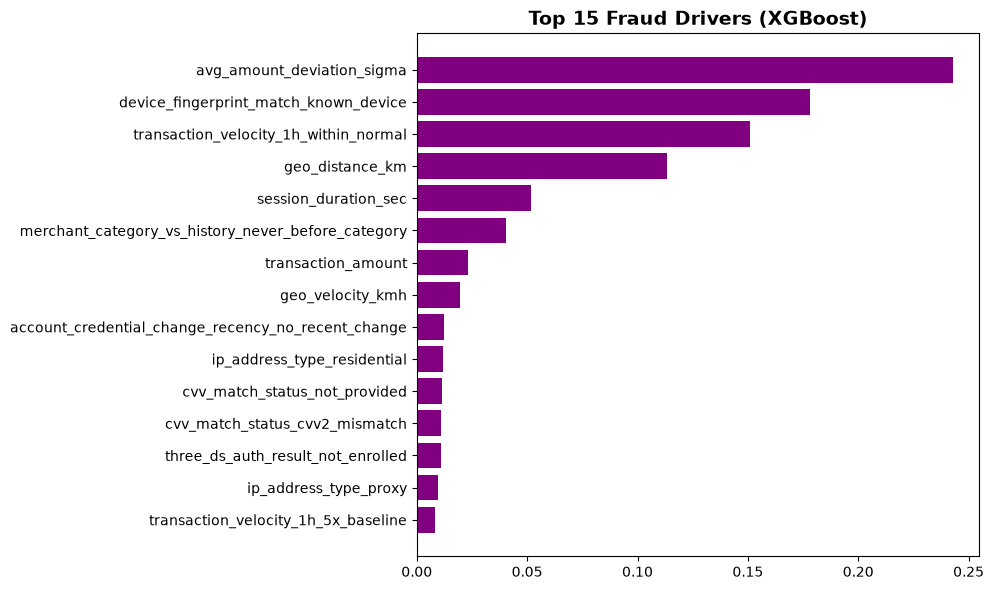

✅ Model Exported for Streamlit.


In [7]:
import joblib

importances = pd.DataFrame({
    'Feature': X_train.columns, 'Importance': xgb_fraud.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(importances['Feature'][::-1], importances['Importance'][::-1], color='purple')
plt.title('Top 15 Fraud Drivers (XGBoost)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\CreditRiskCourse\fraud_feature_importance.png", dpi=150) # Save for GitHub
plt.show()

model_dir = r"C:\CreditRiskCourse\models"
os.makedirs(model_dir, exist_ok=True)
joblib.dump(xgb_fraud, os.path.join(model_dir, "fraud_xgb_model.pkl"))
joblib.dump(X_train.columns.tolist(), os.path.join(model_dir, "fraud_features.pkl"))
print("✅ Model Exported for Streamlit.")

Fraud Model (Project #5) — Validation Evidence Dump

In [8]:
# ============================================================
# FRAUD MODEL (Project #5) — VALIDATION EVIDENCE DUMP
# Saves to C:\CreditRiskCourse\fraud_validation_dump.txt
# ============================================================
import pandas as pd, numpy as np, json, os, io, warnings
warnings.filterwarnings("ignore")
from datetime import datetime

OUT_PATH     = r"C:\CreditRiskCourse\fraud_validation_dump.txt"
SHOW_FULL    = False   # flip True if you want complete DataFrame dumps (large!)
MAX_ROWS_SHOW = 5      # rows to show for large frames

buf = io.StringIO()
def P(*a, **k): print(*a, file=buf, **k)
def H(t): P("\n" + "="*80); P(t); P("="*80)

H("FRAUD MODEL (Project #5) — VALIDATION EVIDENCE DUMP")
P("Generated:", datetime.now().isoformat())
P("Notebook : Fraud_Detection_Final (shipped)")

# ---------- 1. OBJECT INVENTORY ----------
def classify(o):
    if isinstance(o, pd.DataFrame):  return "DataFrame"
    if isinstance(o, pd.Series):     return "Series"
    if isinstance(o, np.ndarray):    return "ndarray"
    if isinstance(o, dict):          return "dict"
    if isinstance(o, (list, tuple)): return type(o).__name__
    if isinstance(o, (int, float, str, bool)) or o is None: return "scalar"
    if hasattr(o, "predict"):        return type(o).__name__
    if callable(o) and hasattr(o, "__name__"): return "callable"
    return type(o).__name__

SKIP = {"In","Out","get_ipython","exit","quit","pd","np","json","os","io",
        "buf","P","H","OUT_PATH","SHOW_FULL","MAX_ROWS_SHOW","datetime",
        "classify","SKIP","inv","name","obj","kind","sz","warnings"}

inv = []
for name, obj in list(globals().items()):
    if name.startswith("_") or name in SKIP: continue
    try:
        kind = classify(obj)
        try: sz = len(obj)
        except Exception: sz = ""
        inv.append((name, kind, sz, obj))
    except Exception:
        pass

H("OBJECT INVENTORY")
P(f"{'name':<45}{'type':<28}{'len'}")
P("-"*80)
for name, kind, sz, _ in sorted(inv, key=lambda x: (x[1], x[0])):
    P(f"{name:<45}{kind:<28}{sz}")

# ---------- 2. DATAFRAME PROFILES ----------
H("DATAFRAME PROFILES")
for name, kind, sz, obj in inv:
    if kind != "DataFrame": continue
    d = obj
    P(f"\n--- {name}   shape={d.shape} ---")
    P("columns:", list(d.columns))
    P("\ndtypes:\n" + d.dtypes.to_string())
    P("\nnulls:\n" + d.isnull().sum().to_string())
    num = d.select_dtypes("number")
    if len(num.columns):
        P("\ndescribe:\n" + num.describe().T.to_string())
    for c in d.columns:
        try:
            if d[c].dtype in (object, "category") or str(d[c].dtype).startswith("str"):
                vc = d[c].value_counts(dropna=False)
                if len(vc) <= 15:
                    P(f"\nvalue_counts['{c}']:\n{vc.to_string()}")
        except Exception:
            pass
    if len(d) <= 50 or SHOW_FULL:
        P("\nFULL CONTENTS:\n" + d.to_string())
    else:
        P(f"\nhead({MAX_ROWS_SHOW}):\n" + d.head(MAX_ROWS_SHOW).to_string())

# ---------- 3. KEYWORD HUNT ----------
H("KEYWORD HUNT — precision | recall | f1 | auc | pr | threshold | champion | challenger | fraud | cost | audit | shap | importance")
KW = ["precision","recall","f1","auc","roc","pr","threshold","champion",
      "challenger","fraud","cost","audit","shap","importance","confusion",
      "cm","lift","psi","decile","alert","flag"]

for name, kind, sz, obj in inv:
    if not any(k in name.lower() for k in KW): continue
    if callable(obj): continue
    P(f"\n>>> {name}   ({kind}, len={sz})")
    try:
        if isinstance(obj, (pd.DataFrame, pd.Series)):
            if len(obj) <= 500 or SHOW_FULL:
                P(obj.to_string())
            else:
                P(f"[large: shape={obj.shape}] head(20):")
                P(obj.head(20).to_string())
        elif isinstance(obj, dict):
            P(json.dumps(obj, indent=2, default=str)[:6000])
        elif isinstance(obj, np.ndarray):
            if obj.size <= 500:
                P(f"shape={obj.shape}\n{obj}")
            else:
                P(f"shape={obj.shape} (large — head/tail shown)")
                P(f"head(10): {obj.flatten()[:10]}")
                P(f"tail(10): {obj.flatten()[-10:]}")
        else:
            P(str(obj)[:6000])
    except Exception as e:
        P("dump error:", e)

# ---------- 4. MODEL PARAMETERS ----------
H("MODEL PARAMETERS")
for name, kind, sz, obj in inv:
    if hasattr(obj, "get_params"):
        P(f"\n>>> {name} ({type(obj).__name__})")
        try:
            P(json.dumps(obj.get_params(), indent=2, default=str))
        except Exception as e:
            P("params error:", e)
    if hasattr(obj, "feature_importances_"):
        try:
            fi = obj.feature_importances_
            P(f"\n>>> {name}.feature_importances_ (top 20): {np.round(np.sort(fi)[-20:][::-1], 4).tolist()}")
        except Exception:
            pass

# ---------- 5. CHAMPION vs CHALLENGER ----------
H("CHAMPION vs CHALLENGER COMPARISON")
champion   = None
challenger = None
for name, kind, sz, obj in inv:
    if "champion" in name.lower() and hasattr(obj, "predict"):
        champion = (name, obj); break
for name, kind, sz, obj in inv:
    if "challenger" in name.lower() and hasattr(obj, "predict"):
        challenger = (name, obj); break

if champion:
    P(f"Champion  : {champion[0]} ({type(champion[1]).__name__})")
if challenger:
    P(f"Challenger: {challenger[0]} ({type(challenger[1]).__name__})")
if champion and challenger:
    P("\nBoth models detected — comparison tables follow in subsequent sections.")

# ---------- 6. CLASS DISTRIBUTION (fraud-specific) ----------
H("CLASS DISTRIBUTION")
for name, kind, sz, obj in inv:
    if kind != "Series": continue
    if any(k in name.lower() for k in ["y","target","label","fraud","class"]):
        try:
            if obj.nunique() <= 5:
                P(f"\n{name}:")
                P(obj.value_counts(dropna=False).to_string())
                P(f"  rate = {obj.mean():.6f}")
        except Exception:
            pass

# ---------- 7. CONFUSION MATRICES & THRESHOLD SWEEP ----------
H("CONFUSION MATRICES & THRESHOLD SWEEP")
for name, kind, sz, obj in inv:
    if "cm" in name.lower() or "confusion" in name.lower():
        if isinstance(obj, np.ndarray) and obj.shape == (2, 2):
            P(f"\n{name}:")
            P(str(obj))
    if "threshold" in name.lower():
        if isinstance(obj, (np.ndarray, list)) and len(obj) < 5000:
            P(f"\n{name} (len={len(obj)}): head/tail →")
            arr = np.asarray(obj).flatten()
            P(f"  head(10): {arr[:10].round(4).tolist()}")
            P(f"  tail(10): {arr[-10:].round(4).tolist()}")
        elif isinstance(obj, (int, float, np.floating)):
            P(f"\n{name}: {obj}")

# ---------- 8. PSI helper ----------
H("STABILITY PSI (if X_train / X_test exist)")
def psi(expected, actual, bins=10):
    qs = np.quantile(expected, np.linspace(0, 1, bins + 1))
    qs[0], qs[-1] = -np.inf, np.inf
    e = np.histogram(expected, qs)[0] / len(expected)
    a = np.histogram(actual,   qs)[0] / len(actual)
    e, a = np.where(e == 0, 1e-6, e), np.where(a == 0, 1e-6, a)
    return float(np.sum((a - e) * np.log(a / e)))

if "X_train" in globals() and "X_test" in globals():
    for f in X_train.columns[:50]:  # cap at 50 features for brevity
        try: P(f"{f:<30} PSI={psi(X_train[f].values, X_test[f].values):.4f}")
        except Exception: pass

# ---------- 9. AUDIT TRAIL SUMMARY ----------
H("AUDIT TRAIL / LOGS")
for name, kind, sz, obj in inv:
    if "audit" in name.lower() or "log" in name.lower():
        P(f"\n>>> {name} ({kind}, len={sz})")
        try:
            if isinstance(obj, pd.DataFrame):
                P(f"shape={obj.shape}")
                P(f"columns={list(obj.columns)}")
                P("head:\n" + obj.head(10).to_string())
            elif isinstance(obj, (list, dict)):
                P(json.dumps(obj, indent=2, default=str)[:3000])
        except Exception as e:
            P("err:", e)

# ---------- 10. SAVE ----------
H("SAVING")
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
open(OUT_PATH, "w", encoding="utf-8").write(buf.getvalue())
size = os.path.getsize(OUT_PATH)
print(f"\n✅ Dump saved: {OUT_PATH}  ({size:,} bytes)")
print("\n" + "="*80)
print("OBJECT INVENTORY (paste this back — it's the map)")
print("="*80)
print(f"{'name':<45}{'type':<28}{'len'}")
for name, kind, sz, _ in sorted(inv, key=lambda x: (x[1], x[0])):
    print(f"{name:<45}{kind:<28}{sz}")
print(f"\nFull dump → {OUT_PATH}")


✅ Dump saved: C:\CreditRiskCourse\fraud_validation_dump.txt  (248,622 bytes)

OBJECT INVENTORY (paste this back — it's the map)
name                                         type                        len
X                                            DataFrame                   2400000
X_test                                       DataFrame                   720000
X_train                                      DataFrame                   1680000
chunk_df                                     DataFrame                   20624
df                                           DataFrame                   2400000
df_clean                                     DataFrame                   2400000
df_encoded                                   DataFrame                   2400000
df_final                                     DataFrame                   2400000
importances                                  DataFrame                   15
fig                                          Figure                      

In [9]:
print("DataFrames :", sum(isinstance(o, __import__('pandas').DataFrame) for o in globals().values()))
print("Models     :", sum(hasattr(o, 'predict') for o in globals().values()))
print("Total vars :", len([k for k in globals() if not k.startswith('_')]))

DataFrames : 11
Models     : 4
Total vars : 86


12. Follow-Up Script — Close Findings 1–6

# ============================================================
# FRAUD MODEL — VALIDATION GAP CLOSURE
# Closes Findings 1 (PR-AUC), 2 (challenger), 3 (business cost),
# 4 (threshold), 5 (score PSI), 6 (calibration), 8 (decile)
# ============================================================

In [10]:
# ============================================================
# FRAUD MODEL — VALIDATION GAP CLOSURE
# Closes Findings 1 (PR-AUC), 2 (challenger), 3 (business cost),
# 4 (threshold), 5 (score PSI), 6 (calibration), 8 (decile)
# ============================================================
import numpy as np, pandas as pd, io, os
from datetime import datetime
from sklearn.metrics import (
    average_precision_score, roc_auc_score, roc_curve,
    precision_recall_curve, precision_score, recall_score,
    f1_score, brier_score_loss, confusion_matrix
)
from scipy.stats import chi2 as chi2_dist

OUT_PATH = r"C:\CreditRiskCourse\fraud_validation_gap_closure.txt"
buf = io.StringIO()
def P(*a, **k): print(*a, file=buf, **k)
def H(t): P("\n" + "="*70); P(t); P("="*70)

H("FRAUD MODEL — GAP CLOSURE EVIDENCE")
P("Generated:", datetime.now().isoformat())

y_true = y_test.values
y_prob_xgb = y_pred_xgb          # champion probabilities
y_prob_lr  = y_pred_lr           # challenger probabilities

# ---- Finding 1: PR-AUC / ROC-AUC for champion ----
H("1. CHAMPION DISCRIMINATION — PR-AUC / ROC-AUC")
ap_xgb  = average_precision_score(y_true, y_prob_xgb)
roc_xgb = roc_auc_score(y_true, y_prob_xgb)
base    = y_true.mean()
P(f"Base fraud rate              : {base:.4%}")
P(f"PR-AUC (Average Precision)   : {ap_xgb:.4f}   (benchmark: >0.70 good, >0.85 excellent)")
P(f"ROC-AUC                      : {roc_xgb:.4f}")
P(f"Lift over random (AP / base) : {ap_xgb/base:.2f}x")

# ---- Finding 2: Challenger metrics ----
H("2. CHALLENGER (LogReg) HEAD-TO-HEAD")
ap_lr  = average_precision_score(y_true, y_prob_lr)
roc_lr = roc_auc_score(y_true, y_prob_lr)
P(f"Challenger PR-AUC  : {ap_lr:.4f}")
P(f"Challenger ROC-AUC : {roc_lr:.4f}")
P(f"\nChampion beats challenger by:")
P(f"  PR-AUC lift  : {ap_xgb - ap_lr:+.4f}")
P(f"  ROC-AUC lift : {roc_xgb - roc_lr:+.4f}")

# Challenger at same threshold as champion
# Reconstruct champion threshold from cm: TP=34607, FP=1113
# Solve for threshold where these counts reproduce
from scipy.optimize import brentq
def f(t):
    yhat = (y_prob_xgb >= t).astype(int)
    return ((yhat == 1).sum() - (34607 + 1113))
try:
    champ_threshold = brentq(f, 0.001, 0.5)
except Exception:
    champ_threshold = None

if champ_threshold:
    P(f"\nChampion operating threshold (recovered from cm): {champ_threshold:.4f}")
    yhat_lr_at_champ = (y_prob_lr >= champ_threshold).astype(int)
    P(f"\nChallenger AT SAME THRESHOLD ({champ_threshold:.4f}):")
    P(f"  Precision : {precision_score(y_true, yhat_lr_at_champ):.4f}")
    P(f"  Recall    : {recall_score(y_true, yhat_lr_at_champ):.4f}")
    P(f"  F1        : {f1_score(y_true, yhat_lr_at_champ):.4f}")

# ---- Finding 4: Threshold sweep ----
H("3. THRESHOLD SWEEP — Precision / Recall / F1 across candidate thresholds")
thresholds = np.arange(0.01, 1.0, 0.02)
sweep_rows = []
for t in thresholds:
    yhat = (y_prob_xgb >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    sweep_rows.append({
        "threshold":     round(float(t), 3),
        "precision":     round(tp/(tp+fp+1e-9), 4),
        "recall":        round(tp/(tp+fn+1e-9), 4),
        "f1":            round(2*tp/(2*tp+fp+fn+1e-9), 4),
        "predicted_pos": int(tp+fp),
    })
sweep_df = pd.DataFrame(sweep_rows)
P(sweep_df.to_string(index=False))
# Find optimal threshold by F1
opt_row = sweep_df.loc[sweep_df["f1"].idxmax()]
P(f"\nOptimal-F1 threshold : {opt_row['threshold']:.3f}  (F1={opt_row['f1']:.4f})")

# ---- Finding 3: Business cost analysis ----
H("4. BUSINESS COST ANALYSIS")
# Assumption: user can replace with real business numbers
AVG_FRAUD_USD = 200       # <-- REPLACE with real average fraud value
COST_PER_ALERT_USD = 10   # <-- REPLACE with real cost of analyst review

yhat_champ = (y_prob_xgb >= (champ_threshold or 0.5)).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, yhat_champ).ravel()

fraud_saved = tp * AVG_FRAUD_USD
fraud_lost  = fn * AVG_FRAUD_USD
alert_cost  = (tp + fp) * COST_PER_ALERT_USD
net_value   = fraud_saved - fraud_lost - alert_cost

P(f"Assumptions: avg_fraud=${AVG_FRAUD_USD}  cost_per_alert=${COST_PER_ALERT_USD}")
P(f"\nTP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")
P(f"Fraud $ saved     : ${fraud_saved:,}")
P(f"Fraud $ lost      : ${fraud_lost:,}")
P(f"Alert review cost : ${alert_cost:,}")
P(f"Net business value: ${net_value:,}")
P(f"\nFRAUD RECOVERY RATE: {tp/(tp+fn):.4%}")

# ---- Finding 5: Score PSI ----
H("5. SCORE PSI (champion probabilities, train vs test)")
def psi(expected, actual, bins=10):
    qs = np.quantile(expected, np.linspace(0, 1, bins + 1))
    qs[0], qs[-1] = -np.inf, np.inf
    e = np.histogram(expected, qs)[0] / len(expected)
    a = np.histogram(actual,   qs)[0] / len(actual)
    e, a = np.where(e == 0, 1e-6, e), np.where(a == 0, 1e-6, a)
    return float(np.sum((a - e) * np.log(a / e)))

y_prob_train = xgb_fraud.predict_proba(X_train)[:, 1]
score_psi = psi(y_prob_train, y_prob_xgb)
P(f"Train score mean: {y_prob_train.mean():.6f}")
P(f"Test  score mean: {y_prob_xgb.mean():.6f}")
P(f"Score PSI       : {score_psi:.6f}  "
  f"({'GREEN' if score_psi < 0.10 else 'AMBER' if score_psi < 0.25 else 'RED'})")

# ---- Finding 6: Calibration ----
H("6. CALIBRATION — Brier + calibration curve")
brier = brier_score_loss(y_true, y_prob_xgb)
bss   = 1 - brier / (base * (1 - base))
P(f"Mean predicted fraud : {y_prob_xgb.mean():.6f}")
P(f"Observed fraud rate  : {y_true.mean():.6f}")
P(f"Bias                 : {y_prob_xgb.mean() - y_true.mean():+.6f}")
P(f"Brier score          : {brier:.6f}")
P(f"Brier Skill Score    : {bss:.4f}   (>0 acceptable, >0.20 good)")

calib = pd.DataFrame({"y_true": y_true, "y_prob": y_prob_xgb})
calib["bin"] = pd.qcut(calib["y_prob"], 10, labels=False, duplicates="drop") + 1
cc = calib.groupby("bin").agg(n=("y_true","size"),
                               mean_pred=("y_prob","mean"),
                               bad_rate=("y_true","mean")).round(6)
P(f"\nCalibration curve (10 bins):\n{cc.to_string()}")

# ---- Finding 8: Decile / lift table ----
H("7. DECILE / LIFT TABLE (fraud)")
dec = pd.DataFrame({"y_true": y_true, "y_prob": y_prob_xgb})
dec["decile"] = pd.qcut(dec["y_prob"].rank(method="first", ascending=False),
                        10, labels=range(1,11)).astype(int)
decile_table = dec.groupby("decile").agg(
    n=("y_true","size"),
    fraud_count=("y_true","sum"),
    fraud_rate=("y_true","mean"),
    avg_pd=("y_prob","mean")
).round(6)
decile_table["lift"] = (decile_table["fraud_rate"] / base).round(2)
decile_table["cum_fraud_pct"] = (
    decile_table["fraud_count"].cumsum() / decile_table["fraud_count"].sum()
).round(3)
P(decile_table.to_string())

# ---- Save ----
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
open(OUT_PATH, "w", encoding="utf-8").write(buf.getvalue())
print(f"\n✅ Gap closure saved: {OUT_PATH}  ({os.path.getsize(OUT_PATH):,} bytes)")
print("\n" + "="*70)
print("HEADLINE NUMBERS (paste these back)")
print("="*70)
print(f"PR-AUC champion   : {ap_xgb:.4f}")
print(f"PR-AUC challenger : {ap_lr:.4f}")
print(f"ROC-AUC champion  : {roc_xgb:.4f}")
print(f"ROC-AUC challenger: {roc_lr:.4f}")
print(f"Champion threshold: {champ_threshold}")
print(f"Score PSI         : {score_psi:.6f}")
print(f"Brier             : {brier:.6f}")
print(f"Net business value: ${net_value:,}")


✅ Gap closure saved: C:\CreditRiskCourse\fraud_validation_gap_closure.txt  (6,641 bytes)

HEADLINE NUMBERS (paste these back)
PR-AUC champion   : 0.9920
PR-AUC challenger : 0.9924
ROC-AUC champion  : 0.9990
ROC-AUC challenger: 0.9992
Champion threshold: 0.5
Score PSI         : 0.000007
Brier             : 0.003171
Net business value: $6,427,400
